# Camada Gold 1: Cliente x Financeiro

Esta Gold cruza o perfil do cliente (gênero, idade, cônjuge e dependentes) com a parte financeira: renda mensal, valor da mensalidade e valor total já pago. No fim, ligamos tudo ao cancelamento (churn), que é o tema comum das três Golds.

Esta Gold responde à primeira frente da pergunta central do projeto (quais características da carteira estão associadas ao cancelamento?): o lado financeiro e o perfil do cliente.

Pergunta principal desta camada: **o perfil e a situação financeira do cliente ajudam a explicar quanto ele paga e se ele cancela?**

## Preparação

Bibliotecas, leitura da Silver e as funções de apoio usadas nos gráficos. As mesmas cores aparecem nas três Golds: azul para a base de clientes e vermelho para o cancelamento.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import hashlib

df_silver = pd.read_csv('../Data/Silver/tabela_silver.csv')
df = df_silver.copy()

COR_BASE = '#4C6A92'
COR_CANCELA = '#C0504D'
COR_REFERENCIA = '#7F7F7F'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

TAXA_GERAL = df['Status_Cancelamento'].mean() * 100
print(f'Clientes: {len(df)} | Taxa geral de cancelamento: {TAXA_GERAL:.1f}%')


def pseudonimizar(id_cliente):
    """Troca o ID real por um código que não permite voltar ao cliente sem a chave.
    Em produção, a chave ficaria fora do código (variável de ambiente ou cofre de senhas)."""
    chave = 'terra-signal-pi2'
    return hashlib.sha256((chave + id_cliente).encode()).hexdigest()[:12]


def brl(valor):
    """Formata número no padrão brasileiro: 5.125,40"""
    return f'{valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def comparar_medias(grupo_a, grupo_b):
    """Diferença de médias entre dois grupos com teste t de Welch.
    p-valor abaixo de 0,05 indica que a diferença dificilmente é obra do acaso."""
    t_stat, p_valor = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)
    return grupo_a.mean(), grupo_b.mean(), p_valor


def taxa_por_grupo(dados, coluna, ordem=None):
    tabela = dados.groupby(coluna, observed=True)['Status_Cancelamento'].agg(Clientes='size', Cancelaram='sum')
    tabela['Taxa_Cancelamento_%'] = (tabela['Cancelaram'] / tabela['Clientes'] * 100).round(1)
    return tabela.reindex(ordem) if ordem else tabela


def grafico_taxa(tabela, titulo, ax=None):
    """Barras horizontais com a taxa de cancelamento de cada grupo e a média geral como referência."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.6 * len(tabela) + 1.5))
    rotulos = [str(i) for i in tabela.index]
    barras = ax.barh(rotulos, tabela['Taxa_Cancelamento_%'], color=COR_CANCELA)
    ax.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in tabela['Taxa_Cancelamento_%']], padding=3)
    ax.axvline(TAXA_GERAL, color=COR_REFERENCIA, linestyle='--', linewidth=1)
    ax.text(TAXA_GERAL, len(tabela) - 0.5, f' média {TAXA_GERAL:.1f}%'.replace('.', ','), color=COR_REFERENCIA, fontsize=9, va='bottom')
    ax.set_xlim(0, max(tabela['Taxa_Cancelamento_%'].max(), TAXA_GERAL) * 1.25)
    ax.invert_yaxis()
    ax.set_xlabel('Taxa de cancelamento (%)')
    ax.set_title(titulo)
    return ax

Clientes: 5633 | Taxa geral de cancelamento: 26.7%


## Construção da tabela Gold

Selecionamos só as colunas do tema e criamos três colunas novas para facilitar os gráficos:

- `Faixa_Renda`: renda dividida em faixas de R$ 2.500.
- `Faixa_Mensalidade`: mensalidade dividida em faixas de 20 em 20 (até 40, 40 a 60, 60 a 80, 80 a 100, acima de 100).
- `Peso_Mensalidade_%`: quanto da renda do cliente vai para a mensalidade.

In [2]:
colunas = ['ID_Cliente', 'Genero', 'Idoso', 'Conjuge', 'Dependentes', 'Tempo_Assinatura',
           'Valores_Mensais', 'Valores_Totais', 'Renda_Mensal', 'Status_Cancelamento']
gold_financeiro = df[colunas].copy()

gold_financeiro['Faixa_Renda'] = pd.cut(
    gold_financeiro['Renda_Mensal'], bins=[0, 2500, 5000, 7500, 10000],
    labels=['Até 2.500', '2.500 a 5.000', '5.000 a 7.500', '7.500 a 10.000'])

gold_financeiro['Faixa_Mensalidade'] = pd.cut(
    gold_financeiro['Valores_Mensais'], bins=[0, 40, 60, 80, 100, 200],
    labels=['Até 40', '40 a 60', '60 a 80', '80 a 100', 'Acima de 100'])

gold_financeiro['Peso_Mensalidade_%'] = (
    gold_financeiro['Valores_Mensais'] / gold_financeiro['Renda_Mensal'] * 100).round(2)

### Proteção do identificador

A tabela Gold é a que vai ser usada para análise e compartilhada com quem faz os gráficos. Por isso, ela não leva o ID real do cliente: o `ID_Cliente` é trocado por um código (`ID_Anonimo`) gerado com SHA-256. O código é sempre o mesmo para o mesmo cliente, então ainda dá para cruzar as três Golds, mas não dá para chegar ao cliente original a partir dele. O texto do feedback também fica de fora.

In [3]:
gold_financeiro.insert(0, 'ID_Anonimo', gold_financeiro['ID_Cliente'].map(pseudonimizar))
gold_financeiro = gold_financeiro.drop(columns='ID_Cliente')

gold_financeiro.to_csv('../Data/Gold/gold_cliente_financeiro.csv', index=False, encoding='utf-8-sig')
print('Formato:', gold_financeiro.shape)
gold_financeiro.head()

Formato: (5633, 13)


,ID_Anonimo,Genero,Idoso,Conjuge,Dependentes,Tempo_Assinatura,Valores_Mensais,Valores_Totais,Renda_Mensal,Status_Cancelamento,Faixa_Renda,Faixa_Mensalidade,Peso_Mensalidade_%
0,7ec889146478,Masculino,False,True,True,52,68.75,3482.85,6532.0,False,5.000 a 7.500,60 a 80,1.05
1,fce4659d5f59,Masculino,False,True,True,33,73.90,2405.05,7634.0,True,7.500 a 10.000,60 a 80,0.97
2,abee89309a29,Feminino,True,False,False,22,20.05,417.00,3628.0,False,2.500 a 5.000,Até 40,0.55
3,14dcb8c4bdf8,Feminino,True,True,True,28,35.90,973.65,7851.0,False,7.500 a 10.000,Até 40,0.46
4,ae6732cedc8a,Masculino,False,False,False,2,70.30,144.00,1691.0,False,Até 2.500,60 a 80,4.16


## Perguntas de orientação

1. Existe diferença entre a renda mensal de diferentes gêneros?
2. Quantos clientes são idosos e quantos desses idosos têm dependentes?
3. Se o cliente possui dependentes, sua renda mensal é maior?
4. A média de cobrança mensal é diferente entre os gêneros?
5. Os idosos possuem cobranças mensais maiores do que os não idosos?
6. Se o cliente possui dependentes, suas cobranças totais são maiores?
7. Se o cliente é idoso, suas cobranças totais são maiores?
8. Renda e mensalidade influenciam o cancelamento?

Nas comparações de médias usamos o teste t de Welch. Ele responde: "essa diferença entre os grupos é grande o bastante para não ser acaso?". Se o p-valor fica abaixo de 0,05, consideramos a diferença real.

### 1. Existe diferença entre a renda mensal de diferentes gêneros?

In [4]:
fem = gold_financeiro.loc[gold_financeiro['Genero'] == 'Feminino', 'Renda_Mensal']
masc = gold_financeiro.loc[gold_financeiro['Genero'] == 'Masculino', 'Renda_Mensal']
media_f, media_m, p = comparar_medias(fem, masc)
print(f'Renda média feminina: R$ {brl(media_f)}')
print(f'Renda média masculina: R$ {brl(media_m)}')
print(f'p-valor: {p:.3f}')

Renda média feminina: R$ 5.124,85
Renda média masculina: R$ 5.085,31
p-valor: 0.601


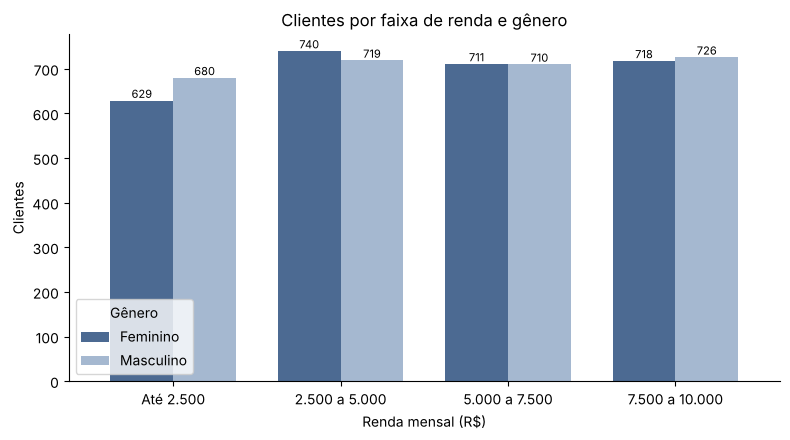

In [5]:
contagem = pd.crosstab(gold_financeiro['Faixa_Renda'], gold_financeiro['Genero'])
ax = contagem.plot(kind='bar', color=[COR_BASE, '#A5B8D0'], figsize=(8, 4.5), rot=0, width=0.75)
for barras in ax.containers:
    ax.bar_label(barras, fontsize=8)
ax.set_title('Clientes por faixa de renda e gênero')
ax.set_xlabel('Renda mensal (R$)')
ax.set_ylabel('Clientes')
ax.legend(title='Gênero')
plt.tight_layout()
plt.show()

**Resposta:** não. As médias ficam a menos de R$ 40 uma da outra e o p-valor é bem maior que 0,05. Homens e mulheres aparecem em quantidades parecidas em todas as faixas de renda.

Um detalhe que aparece aqui e se repete nas próximas perguntas: as quatro faixas de renda têm praticamente o mesmo número de clientes. A renda está espalhada de forma uniforme entre R$ 100 e R$ 10.000, sem concentração em nenhuma faixa, o que é pouco comum numa base real e indica que essa coluna foi gerada de forma artificial na base fictícia.

### 2. Quantos clientes são idosos e quantos desses idosos têm dependentes?

In [6]:
idosos = gold_financeiro[gold_financeiro['Idoso']]
print(f"Idosos: {len(idosos)} de {len(gold_financeiro)} clientes ({len(idosos) / len(gold_financeiro):.1%})")
print(f"Idosos com dependentes: {idosos['Dependentes'].sum()} ({idosos['Dependentes'].mean():.1%} dos idosos)")
print(f"Não idosos com dependentes: {gold_financeiro.loc[~gold_financeiro['Idoso'], 'Dependentes'].mean():.1%}")

Idosos: 928 de 5633 clientes (16.5%)
Idosos com dependentes: 69 (7.4% dos idosos)
Não idosos com dependentes: 34.3%


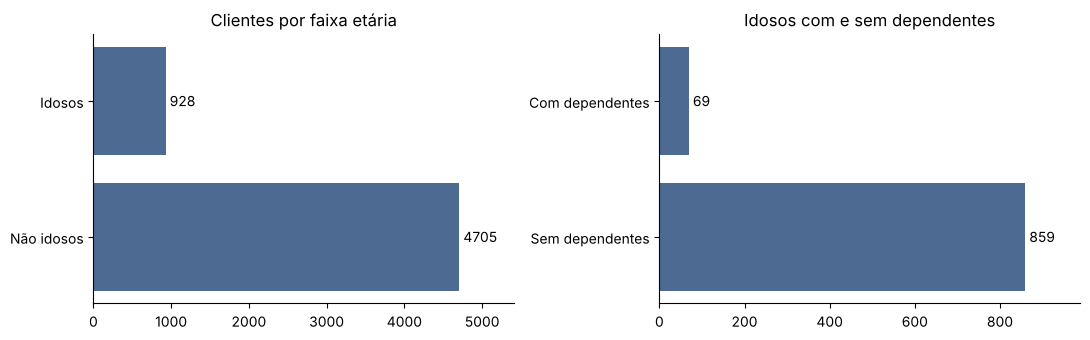

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

contagem_idoso = gold_financeiro['Idoso'].map({True: 'Idosos', False: 'Não idosos'}).value_counts()
barras = axes[0].barh(contagem_idoso.index, contagem_idoso.values, color=COR_BASE)
axes[0].bar_label(barras, padding=3)
axes[0].set_title('Clientes por faixa etária')
axes[0].set_xlim(0, contagem_idoso.max() * 1.15)

dep_idosos = idosos['Dependentes'].map({True: 'Com dependentes', False: 'Sem dependentes'}).value_counts()
barras = axes[1].barh(dep_idosos.index, dep_idosos.values, color=COR_BASE)
axes[1].bar_label(barras, padding=3)
axes[1].set_title('Idosos com e sem dependentes')
axes[1].set_xlim(0, dep_idosos.max() * 1.15)

plt.tight_layout()
plt.show()

**Resposta:** os idosos são 16,5% da carteira (928 clientes). Só 7,4% deles têm dependentes, contra mais de um terço entre os não idosos. Faz sentido: na maioria dos casos, os filhos de clientes idosos já são adultos e não dependem mais deles.

### 3. Se o cliente possui dependentes, sua renda mensal é maior?

In [8]:
com_dep = gold_financeiro.loc[gold_financeiro['Dependentes'], 'Renda_Mensal']
sem_dep = gold_financeiro.loc[~gold_financeiro['Dependentes'], 'Renda_Mensal']
media_c, media_s, p = comparar_medias(com_dep, sem_dep)
print(f'Renda média com dependentes: R$ {brl(media_c)}')
print(f'Renda média sem dependentes: R$ {brl(media_s)}')
print(f'p-valor: {p:.3f}')

Renda média com dependentes: R$ 5.083,25
Renda média sem dependentes: R$ 5.114,21
p-valor: 0.707


**Resposta:** não. A renda média é praticamente a mesma nos dois grupos e a diferença não é significativa. Ter dependentes não indica renda maior nesta base.

### 4. A média de cobrança mensal é diferente entre os gêneros?

In [9]:
fem = gold_financeiro.loc[gold_financeiro['Genero'] == 'Feminino', 'Valores_Mensais']
masc = gold_financeiro.loc[gold_financeiro['Genero'] == 'Masculino', 'Valores_Mensais']
media_f, media_m, p = comparar_medias(fem, masc)
print(f'Mensalidade média feminina: {brl(media_f)}')
print(f'Mensalidade média masculina: {brl(media_m)}')
print(f'p-valor: {p:.3f}')

Mensalidade média feminina: 65,40
Mensalidade média masculina: 63,81
p-valor: 0.048


**Resposta:** na prática, não. O teste fica bem no limite (p-valor de 0,048), mas a diferença é de 1,60 por mês, cerca de 2,5%. É uma diferença pequena demais para mudar qualquer decisão sobre preço ou oferta.

### 5. Os idosos possuem cobranças mensais maiores do que os não idosos?

### 6. Se o cliente possui dependentes, suas cobranças totais são maiores?

### 7. Se o cliente é idoso, suas cobranças totais são maiores?

As três perguntas comparam valores pagos entre grupos, então respondemos juntas numa única tabela.

In [10]:
comparacoes = []
for grupo in ['Idoso', 'Dependentes']:
    for valor in ['Valores_Mensais', 'Valores_Totais']:
        sim = gold_financeiro.loc[gold_financeiro[grupo], valor]
        nao = gold_financeiro.loc[~gold_financeiro[grupo], valor]
        media_sim, media_nao, p = comparar_medias(sim, nao)
        comparacoes.append({'Grupo': grupo, 'Valor': valor,
                            'Média com': round(media_sim, 2), 'Média sem': round(media_nao, 2),
                            'Diferença %': round((media_sim / media_nao - 1) * 100, 1),
                            'p-valor': round(p, 4)})
tabela_comparacoes = pd.DataFrame(comparacoes)
tabela_comparacoes

,Grupo,Valor,Média com,Média sem,Diferença %,p-valor
0,Idoso,Valores_Mensais,79.93,61.58,29.8,0.0
1,Idoso,Valores_Totais,2817.17,2164.58,30.1,0.0
2,Dependentes,Valores_Mensais,59.04,66.98,-11.9,0.0
3,Dependentes,Valores_Totais,2479.48,2183.58,13.6,0.0


In [11]:
tempo_medio = gold_financeiro.groupby('Dependentes')['Tempo_Assinatura'].mean().round(1)
print('Tempo médio de assinatura (meses) sem e com dependentes:', tempo_medio.to_dict())
tempo_medio_idoso = gold_financeiro.groupby('Idoso')['Tempo_Assinatura'].mean().round(1)
print('Tempo médio de assinatura (meses) não idosos e idosos:', tempo_medio_idoso.to_dict())

Tempo médio de assinatura (meses) sem e com dependentes: {False: 29.7, True: 38.4}
Tempo médio de assinatura (meses) não idosos e idosos: {False: 32.1, True: 33.2}


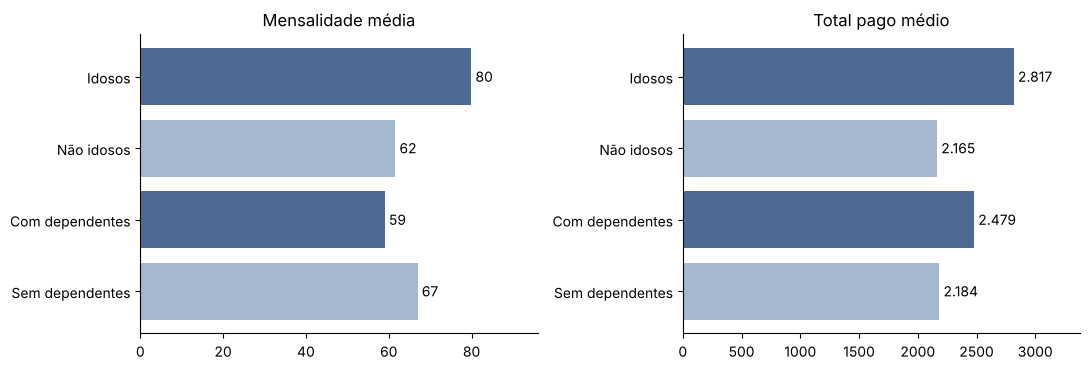

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, valor, titulo in zip(axes, ['Valores_Mensais', 'Valores_Totais'],
                             ['Mensalidade média', 'Total pago médio']):
    medias = pd.Series({
        'Idosos': gold_financeiro.loc[gold_financeiro['Idoso'], valor].mean(),
        'Não idosos': gold_financeiro.loc[~gold_financeiro['Idoso'], valor].mean(),
        'Com dependentes': gold_financeiro.loc[gold_financeiro['Dependentes'], valor].mean(),
        'Sem dependentes': gold_financeiro.loc[~gold_financeiro['Dependentes'], valor].mean(),
    })
    barras = ax.barh(medias.index, medias.values, color=[COR_BASE, '#A5B8D0', COR_BASE, '#A5B8D0'])
    ax.bar_label(barras, labels=[f'{v:,.0f}'.replace(',', '.') for v in medias.values], padding=3)
    ax.set_xlim(0, medias.max() * 1.2)
    ax.invert_yaxis()
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

**Respostas:**

- **5.** Sim. Idosos pagam em média 30% a mais por mês (79,9 contra 61,6). Na Gold 2 aparece o motivo: mais de 70% dos idosos usam fibra óptica, que é o plano mais caro.
- **6.** Sim, mas não porque gastam mais por mês. Quem tem dependentes paga uma mensalidade um pouco menor, só que fica mais tempo como cliente (cerca de 38 meses contra 30). Como o total é mensalidade × tempo, o total acaba maior.
- **7.** Sim. Idosos acumulam um total cerca de 30% maior. Como o tempo de casa deles é quase igual ao dos não idosos (33 contra 32 meses), essa diferença vem toda da mensalidade mais alta.

O valor total pago depende principalmente do tempo de casa. Por isso, nas próximas análises de cancelamento usamos a mensalidade, que mostra melhor o "peso" do serviço para o cliente.

### 8. Renda e mensalidade influenciam o cancelamento?

In [13]:
cancelou = gold_financeiro.loc[gold_financeiro['Status_Cancelamento'], 'Renda_Mensal']
ficou = gold_financeiro.loc[~gold_financeiro['Status_Cancelamento'], 'Renda_Mensal']
m1, m2, p = comparar_medias(cancelou, ficou)
print(f'Renda média de quem cancelou: R$ {brl(m1)} | de quem ficou: R$ {brl(m2)} | p-valor: {p:.3f}')

cancelou = gold_financeiro.loc[gold_financeiro['Status_Cancelamento'], 'Valores_Mensais']
ficou = gold_financeiro.loc[~gold_financeiro['Status_Cancelamento'], 'Valores_Mensais']
m1, m2, p = comparar_medias(cancelou, ficou)
print(f'Mensalidade média de quem cancelou: {brl(m1)} | de quem ficou: {brl(m2)} | p-valor: {p:.2e}')

Renda média de quem cancelou: R$ 5.167,94 | de quem ficou: R$ 5.082,03 | p-valor: 0.314
Mensalidade média de quem cancelou: 74,61 | de quem ficou: 60,96 | p-valor: 2.57e-62


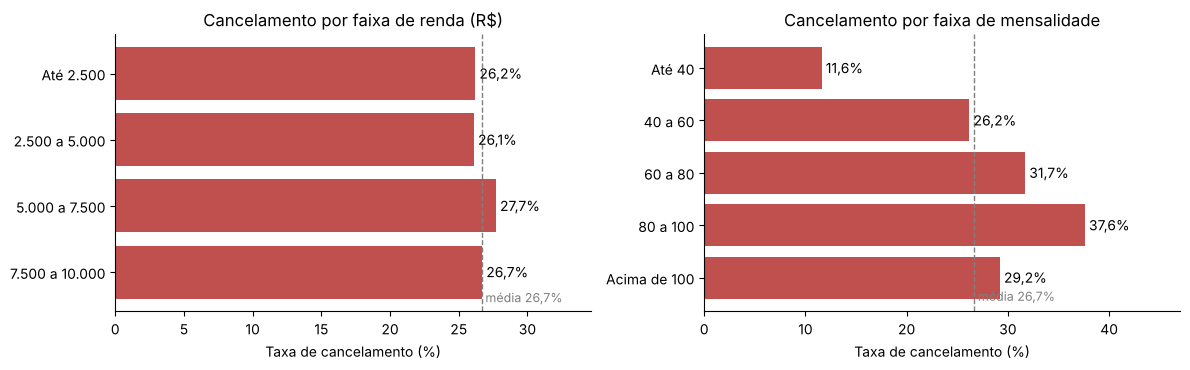

,Clientes,Cancelaram,Taxa_Cancelamento_%
Faixa_Mensalidade,,,
Até 40,1490,173,11.6
40 a 60,862,226,26.2
60 a 80,1155,366,31.7
80 a 100,1400,526,37.6
Acima de 100,726,212,29.2


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
grafico_taxa(taxa_por_grupo(gold_financeiro, 'Faixa_Renda'), 'Cancelamento por faixa de renda (R$)', ax=axes[0])
grafico_taxa(taxa_por_grupo(gold_financeiro, 'Faixa_Mensalidade'), 'Cancelamento por faixa de mensalidade', ax=axes[1])
plt.tight_layout()
plt.show()

taxa_por_grupo(gold_financeiro, 'Faixa_Mensalidade')

**Resposta:** a renda não influencia. A taxa de cancelamento fica entre 26% e 28% em todas as faixas de renda, colada na média geral.

A mensalidade influencia bastante. Quem cancelou pagava em média cerca de 75 por mês, contra 61 de quem ficou. Clientes que pagam até 40 cancelam bem abaixo da média, enquanto as faixas de 60 a 100 ficam bem acima. A faixa acima de 100 volta a cair um pouco: são clientes com pacote completo, que já estão há mais tempo na empresa (isso é aprofundado nas Golds 2 e 3).

## Conclusões da Gold 1

- Gênero não muda a renda, quase não muda a mensalidade e não muda o cancelamento (27,2% entre mulheres e 26,2% entre homens). Não vale segmentar ações por gênero.
- A renda mensal não explica nada na base: está distribuída por igual e não muda o gasto nem o cancelamento. Por isso ela não é usada como variável de decisão nas outras Golds.
- Idosos são 16,5% da carteira, pagam cerca de 30% a mais por mês e, como mostram as próximas Golds, também cancelam mais.
- O valor total pago é consequência do tempo de casa. Quem tem dependentes paga menos por mês, mas fica mais tempo.
- A mensalidade é a variável financeira que realmente se relaciona com o cancelamento: quanto mais cara, maior a chance de sair, até a faixa de 100.

**Como a Terra Signal pode usar:** não gastar esforço segmentando campanhas de retenção por gênero ou renda, e acompanhar com mais atenção clientes com mensalidade entre 60 e 100, que é a faixa que mais cancela.

A pergunta que fica para as próximas Golds é: o que faz a mensalidade ficar alta (serviços contratados) e o que segura o cliente mesmo pagando mais (tipo de contrato e tempo de casa)?